# Mini-projet — Data Mining
## Segmentation client et détection des clients à forte valeur (e-commerce)

**Master Big Data, IA & Applications Avancées - Realise par: Bilal jellaoui  -  Encadrante: Prof. BAQQASS Sanae**

---

### Contexte métier

Un site e-commerce britannique enregistre chaque transaction de ses clients. Comme toute
entreprise avec une base client, il doit répondre à une question simple mais coûteuse à
mal résoudre : **quels clients faut-il fidéliser en priorité, et lesquels sont en train de
partir ?** Répondre à cette question avec des données plutôt qu'à l'instinct est l'une des
missions les plus classiques des équipes CRM / Data Marketing, aussi bien en e-commerce
(Jumia, Glovo) qu'en retail (Marjane, Aswak Assalam) ou en banque - et un cas d'usage
récurrent dans les missions de conseil data (Capgemini, Deloitte...).

### Ce que nous allons faire (Objectif du projet) 

| Consigne | Réalisé dans ce notebook |
|---|---|
| EDA | Sections 2 à 6 |
| Prétraitement | Sections 3 à 7 |
| 1 méthode prédictive | Section 9 - Régression logistique |
| 1 méthode descriptive | Section 10 - K-means (segmentation RFM) |
| Rapport avec interprétation | Une cellule d'interprétation après chaque résultat |

### Lien avec le cours de Séance en Séance(Application pratique du cours)

- **Séance 1** (KDD) : ce notebook suit les 5 étapes du processus KDD vues en cours - sélection,
  prétraitement, transformation, data mining, interprétation - comme rappelé en introduction.
- **Séance 2** (Prétraitement) : typologie des variables, valeurs manquantes réelles,
  doublons, outliers (IQR), encodage, corrélation - sections 2 à 7.
- **Séance 3** (Régression) : cible binaire dérivée par seuil médian (même méthode que le
  TP3 du cours sur le dataset Diabetes), régression logistique, odds ratio, métriques
  (accuracy, precision, rappel, F1, AUC) - section 9.
- **Séance 4** (Classification & Clustering) : K-means, méthode du coude, `pd.crosstab()`
  cluster × classe réelle, comme dans le TP4 du cours sur Iris - section 10.

### dataset que nous allons utiliser (Jeu de données)

**541 909 transactions réelles**, 8 variables, d'un site e-commerce britannique (2010-2011) :
numéro de facture, code produit, description, quantité, date, prix unitaire, identifiant
client, pays. Environ **25% des transactions n'ont pas d'identifiant client** (achats
invités) - une vraie valeur manquante, non simulée.

Source : "Online Retail" (UCI Machine Learning Repository), l'un des jeux de données les
plus utilisés au monde pour l'analyse RFM (Récence, Fréquence, Montant) et la segmentation
client.


## 1. Chargement du jeu de données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

COULEUR_OR = "#c9a227"
COULEUR_MARINE = "#1f2937"
COULEUR_BLEU = "#4c72b0"
COULEUR_ORANGE = "#dd8452"

url = "../data/dataset.csv.zip"   # chemin relatif : voir README (dossier data/)
df = pd.read_csv(url, compression="zip", encoding="latin1")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
print("Dimensions :", df.shape)
df.info()

Dimensions : (541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 69.3 MB


**Interprétation :** 541 909 transactions et 8 colonnes. On distingue :
- des **identifiants** : `InvoiceNo` (numéro de facture), `StockCode` (code produit),
  `CustomerID` (identifiant client)
- une **variable textuelle libre** : `Description`
- des **variables quantitatives** : `Quantity` (discrète), `UnitPrice` (continue)
- une **variable temporelle** : `InvoiceDate`
- une **variable qualitative nominale** : `Country`

Contrairement au Titanic (TP1) où les valeurs manquantes étaient visibles dès le `head()`,
ici il faut creuser un peu plus : `df.info()` montre déjà que `Description` et `CustomerID`
ont moins de 541 909 valeurs non-nulles.


## 2. Diagnostic de la qualité des données 

In [3]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"manquants": missing, "%": missing_pct}).query("manquants > 0").sort_values("%", ascending=False)

,manquants,%
CustomerID,135080,24.93
Description,1454,0.27


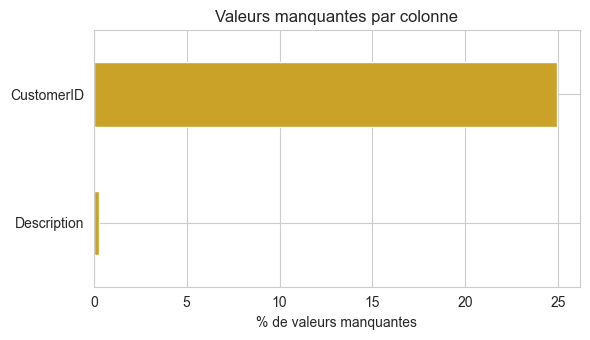

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
missing_pct[missing_pct > 0].sort_values().plot(kind="barh", ax=ax, color=COULEUR_OR)
ax.set_xlabel("% de valeurs manquantes")
ax.set_title("Valeurs manquantes par colonne")
plt.tight_layout()
plt.show()

**Interprétation :** `CustomerID` manque sur **24,9% des transactions** — un taux
élevé, très probablement **MNAR** (Missing Not At Random) : ce sont des achats effectués
sans compte client (achat "invité"), donc l'absence dépend directement de la nature de
l'achat. `Description` manque sur 0,3% des lignes, un taux négligeable.

Comme la variable cible de ce projet sera construite **par client** (`CustomerID`), les
transactions sans identifiant ne peuvent tout simplement pas être rattachées à un client :
contrairement à une imputation classique (moyenne/mode), on ne peut pas "inventer" un
identifiant client. La suppression de ces lignes est donc la seule stratégie valide ici
(cf. Séance 2 : "Suppression de la ligne — quand très peu de lignes concernées" ; ici le
volume est plus élevé, mais la nature de la variable ne laisse pas d'alternative).


In [5]:
print("Doublons :", df.duplicated().sum())

df = df.dropna(subset=["CustomerID"])
df = df.drop_duplicates()

print("Après nettoyage :", df.shape)
print("Valeurs manquantes restantes :", df.isna().sum().sum())

Doublons : 5268
Après nettoyage : (401604, 8)
Valeurs manquantes restantes : 0


## 3. Détection des valeurs aberrantes (outliers) 

In [6]:
print("Quantités négatives (retours) :", (df["Quantity"] < 0).sum())
print("Prix unitaires nuls ou négatifs   :", (df["UnitPrice"] <= 0).sum())
print("Factures annulées (préfixe 'C')   :", df["InvoiceNo"].astype(str).str.startswith("C").sum())

Quantités négatives (retours) : 8872
Prix unitaires nuls ou négatifs   : 40
Factures annulées (préfixe 'C')   : 8872


**Interprétation :** les quantités négatives correspondent à des **retours produits**
(annulation de commande, code facture préfixé par `C`) — ce ne sont pas des erreurs de
saisie mais une information métier légitime. Comme l'objectif est d'analyser le
**comportement d'achat réel**, on retire les retours/annulations et les prix nuls, qui ne
représentent pas des ventes effectives.


In [7]:
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
print("Taille après filtrage des retours/annulations :", df.shape)

Taille après filtrage des retours/annulations : (392692, 8)


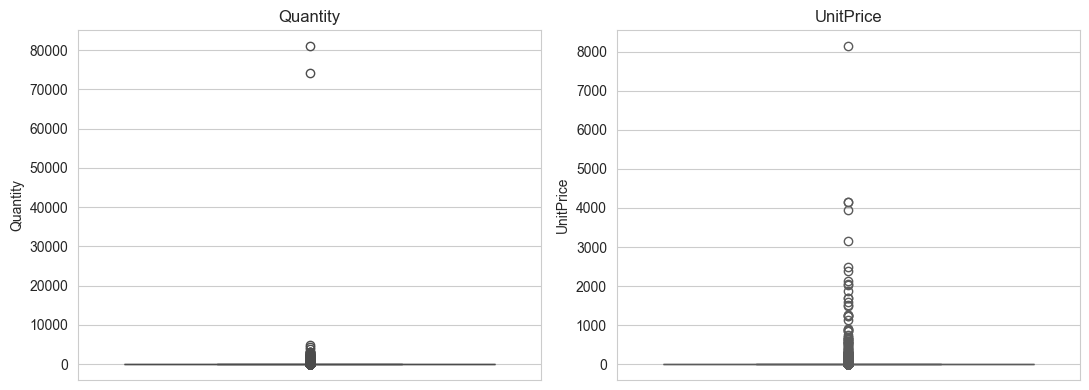

Quantity     :  25616 outliers (6.5%)
UnitPrice    :  34112 outliers (8.7%)


In [8]:
df["MontantLigne"] = df["Quantity"] * df["UnitPrice"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(y=df["Quantity"], ax=axes[0], color=COULEUR_BLEU)
axes[0].set_title("Quantity")
sns.boxplot(y=df["UnitPrice"], ax=axes[1], color=COULEUR_ORANGE)
axes[1].set_title("UnitPrice")
plt.tight_layout()
plt.show()

def outliers_iqr(serie):
    Q1, Q3 = serie.quantile(0.25), serie.quantile(0.75)
    IQR = Q3 - Q1
    return serie[(serie < Q1 - 1.5*IQR) | (serie > Q3 + 1.5*IQR)]

for col in ["Quantity", "UnitPrice"]:
    out = outliers_iqr(df[col])
    print(f"{col:12s} : {len(out):6d} outliers ({len(out)/len(df)*100:.1f}%)")

**Interprétation :** de nombreux outliers hauts sur `Quantity` (achats en gros,
probablement des revendeurs professionnels) et sur `UnitPrice` (quelques articles de luxe).
on détecte ces valeurs sans les supprimer
automatiquement : ce sont des clients au comportement d'achat différent, pas des erreurs —
ils seront justement mis en évidence par la segmentation en section 10.


## 4. Construction de la table client — Analyse RFM

**Étape spécifique à ce projet :** contrairement aux TP du cours qui travaillent directement
sur des données déjà au niveau "individu", ce dataset est au niveau **transaction**. Il faut
d'abord agréger les transactions par client pour obtenir 3 indicateurs classiques du
marketing client :

- **Récence (R)** : nombre de jours depuis le dernier achat (plus c'est bas, mieux c'est)
- **Fréquence (F)** : nombre de commandes distinctes passées
- **Montant (M)** : total dépensé par le client


In [9]:
date_reference = df["InvoiceDate"].apply(pd.to_datetime).max() + pd.Timedelta(days=1)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

rfm = df.groupby("CustomerID").agg(
    Recence=("InvoiceDate", lambda x: (date_reference - x.max()).days),
    Frequence=("InvoiceNo", "nunique"),
    Montant=("MontantLigne", "sum"),
    Pays=("Country", "first")
).reset_index()

print("Nombre de clients :", rfm.shape[0])
rfm.head()

Nombre de clients : 4338


,CustomerID,Recence,Frequence,Montant,Pays
0,12346.0,326,1,77183.60,United Kingdom
1,12347.0,2,7,4310.00,Iceland
2,12348.0,75,4,1797.24,Finland
3,12349.0,19,1,1757.55,Italy
4,12350.0,310,1,334.40,Norway


## 5. Statistiques descriptives et corrélations 

In [10]:
rfm[["Recence", "Frequence", "Montant"]].describe().round(1)

,Recence,Frequence,Montant
count,4338.0,4338.0,4338.0
mean,92.5,4.3,2048.7
std,100.0,7.7,8985.2
min,1.0,1.0,3.8
25%,18.0,1.0,306.5
50%,51.0,2.0,668.6
75%,142.0,5.0,1660.6
max,374.0,209.0,280206.0


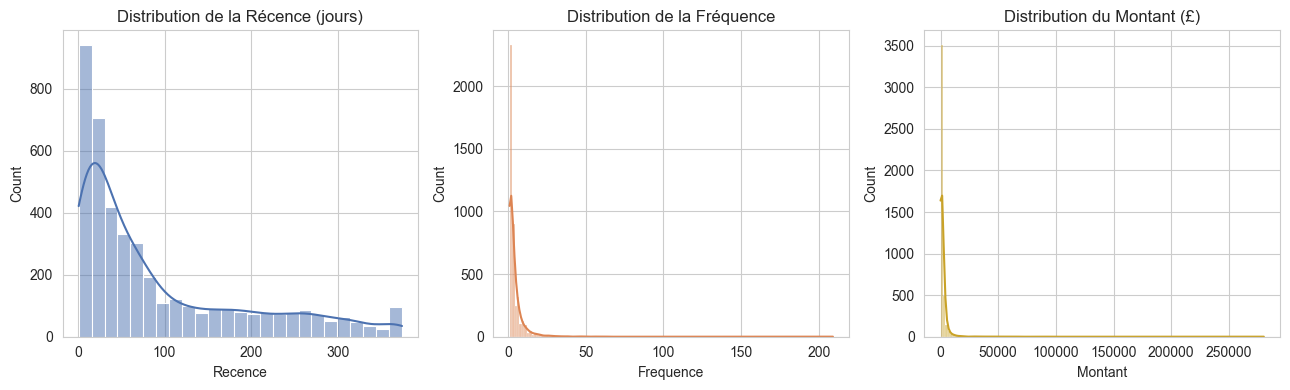

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
sns.histplot(rfm["Recence"], kde=True, ax=axes[0], color=COULEUR_BLEU)
axes[0].set_title("Distribution de la Récence (jours)")
sns.histplot(rfm["Frequence"], kde=True, ax=axes[1], color=COULEUR_ORANGE)
axes[1].set_title("Distribution de la Fréquence")
sns.histplot(rfm["Montant"], kde=True, ax=axes[2], color=COULEUR_OR)
axes[2].set_title("Distribution du Montant (£)")
plt.tight_layout()
plt.show()

**Interprétation :** les trois distributions sont fortement asymétriques à droite —
la majorité des clients achètent peu et récemment, mais une minorité de gros clients tire
fortement les moyennes vers le haut. C'est un schéma très classique en e-commerce (loi de
Pareto : une minorité de clients génère l'essentiel du chiffre d'affaires), et c'est
justement ce que la segmentation va permettre d'isoler.


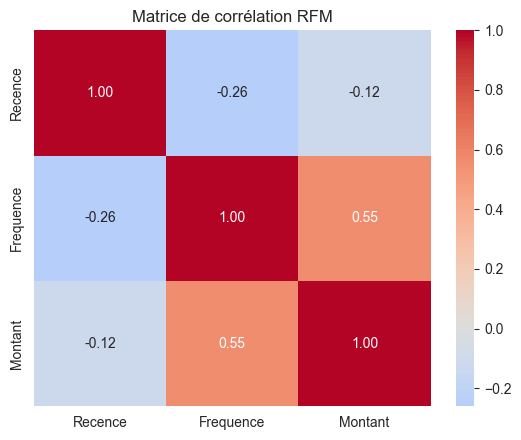

In [12]:
plt.figure(figsize=(5.5, 4.5))
correlation = rfm[["Recence", "Frequence", "Montant"]].corr()
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation RFM")
plt.tight_layout()
plt.show()

**Lecture :** `Frequence` et `Montant` sont fortement corrélées positivement (logique :
un client qui commande souvent dépense davantage au total), tandis que `Recence` est
corrélée négativement aux deux autres — un client qui a acheté récemment tend aussi à être
plus fréquent et plus dépensier. Ce sont des relations cohérentes, pas de colinéarité
suspecte qui poserait un problème pour la régression logistique de la section 9.


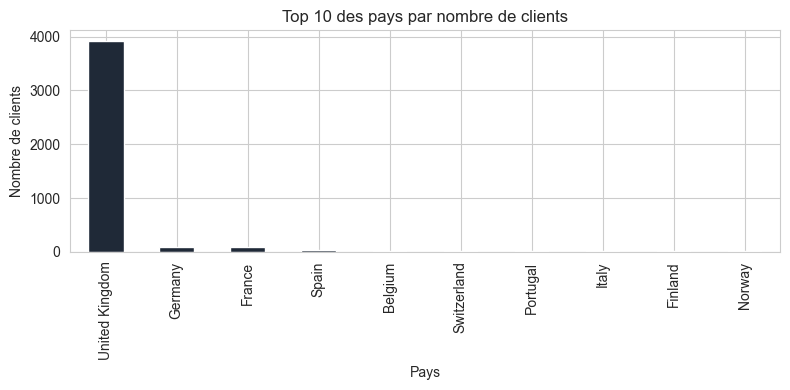

In [13]:
top10_pays = rfm["Pays"].value_counts().head(10)
plt.figure(figsize=(8, 4))
top10_pays.plot(kind="bar", color=COULEUR_MARINE)
plt.title("Top 10 des pays par nombre de clients")
plt.ylabel("Nombre de clients")
plt.tight_layout()
plt.show()

**Interprétation métier :** le Royaume-Uni domine très largement la clientèle (site
britannique), suivi de l'Allemagne et de la France — cohérent avec un e-commerce basé au
UK. Cette variable `Pays` sera utilisée comme point de comparaison externe pour la
segmentation en section 10.


## 6. Construction de la cible : client à forte valeur (VIP)

**Méthode:** on dérive une cible
binaire à partir d'une variable continue en la comparant à sa médiane.


In [14]:
seuil_vip = rfm["Montant"].median()
rfm["VIP"] = (rfm["Montant"] > seuil_vip).astype(int)

print(f"Seuil médian de Montant : {seuil_vip:.2f} £")
print(rfm["VIP"].value_counts(normalize=True).round(3) * 100)

Seuil médian de Montant : 668.57 £
VIP
1    50.0
0    50.0
Name: proportion, dtype: float64


**Interprétation :** par construction (seuil médian), exactement 50% des clients sont
classés VIP. C'est un choix pédagogique cohérent avec la méthode du cours ; en conditions
réelles, une banque ou un site e-commerce fixerait ce seuil selon un objectif business
(ex : le top 20% des clients qui génèrent 80% du chiffre d'affaires).


## 7. Encodage et préparation pour la modélisation 

In [15]:
# Country : nominale à forte cardinalité (38 pays) -> on regroupe les pays rares
top_pays = rfm["Pays"].value_counts().head(6).index
rfm["Pays_groupe"] = rfm["Pays"].where(rfm["Pays"].isin(top_pays), "Autre")

rfm_encoded = pd.get_dummies(rfm, columns=["Pays_groupe"], drop_first=True)
rfm_encoded = rfm_encoded.drop(columns=["Pays"])
rfm_encoded.head()

,CustomerID,Recence,Frequence,Montant,VIP,Pays_groupe_Belgium,Pays_groupe_France,Pays_groupe_Germany,Pays_groupe_Spain,Pays_groupe_Switzerland,Pays_groupe_United Kingdom
0,12346.0,326,1,77183.60,1,False,False,False,False,False,True
1,12347.0,2,7,4310.00,1,False,False,False,False,False,False
2,12348.0,75,4,1797.24,1,False,False,False,False,False,False
3,12349.0,19,1,1757.55,1,False,False,False,False,False,False
4,12350.0,310,1,334.40,0,False,False,False,False,False,False


## 8. Split train/test et standardisation *(règle d'or)*

On sépare train/test **avant** de standardiser, et on ajuste (`fit`) le scaler uniquement
sur le train pour éviter toute fuite d'information (*data leakage*).


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# On exclut explicitement CustomerID, Montant, VIP, ainsi que 'cluster'/'cluster_cah'
# (variables de la méthode descriptive, section 10-11, à ne jamais utiliser comme prédicteurs ici)
colonnes_a_exclure = [c for c in ["CustomerID", "Montant", "VIP", "cluster", "cluster_cah"] if c in rfm_encoded.columns]
X = rfm_encoded.drop(columns=colonnes_a_exclure)
y = rfm_encoded["VIP"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

colonnes_a_standardiser = ["Recence", "Frequence"]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[colonnes_a_standardiser] = scaler.fit_transform(X_train[colonnes_a_standardiser])
X_test_scaled[colonnes_a_standardiser] = scaler.transform(X_test[colonnes_a_standardiser])

print("Train :", X_train_scaled.shape, " Test :", X_test_scaled.shape)

Train : (3470, 8)  Test : (868, 8)


## 9. Méthode prédictive — Régression logistique 

**Objectif business :** prédire si un client est susceptible d'être un client VIP à partir
de son comportement d'achat (récence, fréquence, pays), pour orienter les actions marketing
avant même d'attendre que le montant dépensé le confirme.


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve)

logreg = LogisticRegression(max_iter=5000)
logreg.fit(X_train_scaled, y_train)

y_pred = logreg.predict(X_test_scaled)
y_proba = logreg.predict_proba(X_test_scaled)[:, 1]

print("Accuracy  :", round(accuracy_score(y_test, y_pred), 3))
print("Précision :", round(precision_score(y_test, y_pred), 3))
print("Rappel    :", round(recall_score(y_test, y_pred), 3))
print("F1-score  :", round(f1_score(y_test, y_pred), 3))
print("AUC       :", round(roc_auc_score(y_test, y_proba), 3))

Accuracy  : 0.836
Précision : 0.849
Rappel    : 0.818
F1-score  : 0.833
AUC       : 0.911


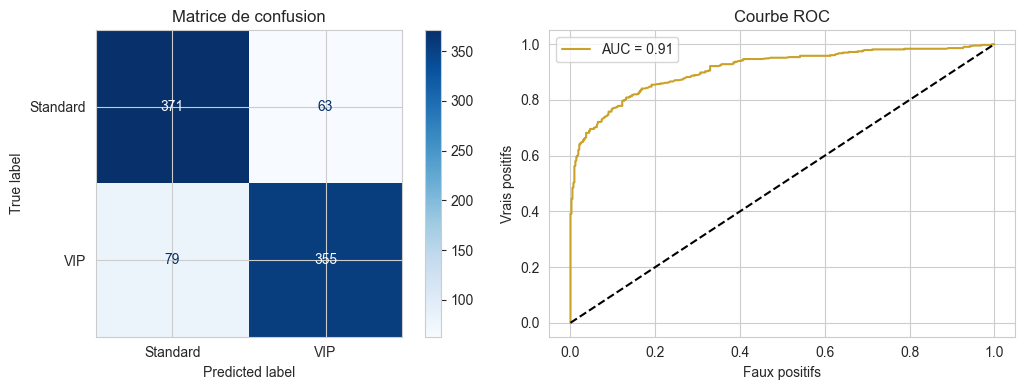

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                        display_labels=["Standard", "VIP"]).plot(ax=axes[0], cmap="Blues")
axes[0].set_title("Matrice de confusion")

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color=COULEUR_OR, label=f"AUC = {roc_auc_score(y_test, y_proba):.2f}")
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_xlabel("Faux positifs")
axes[1].set_ylabel("Vrais positifs")
axes[1].set_title("Courbe ROC")
axes[1].legend()

plt.tight_layout()
plt.show()

In [19]:
odds_ratios = np.exp(logreg.coef_[0])
pd.Series(odds_ratios, index=X_train_scaled.columns).sort_values(ascending=False)

Frequence                     1950.038627
Pays_groupe_Switzerland          2.275149
Pays_groupe_Belgium              1.244412
Pays_groupe_Spain                1.109232
Recence                          0.738833
Pays_groupe_Germany              0.558485
Pays_groupe_France               0.402124
Pays_groupe_United Kingdom       0.284425
dtype: float64

**Interprétation métier (odds ratio) :** `Frequence` a l'effet le plus fort et positif
sur le statut VIP — logique, puisque commander souvent est le principal moteur du montant
total dépensé. `Recence` a un effet négatif marqué : plus un client a acheté récemment, plus
il a de chances d'être VIP (cohérent avec la corrélation observée en section 5).

→ **Action concrète pour l'entreprise :** surveiller la fréquence d'achat et la récence en
temps réel permet d'anticiper le statut VIP d'un client **avant** que son montant cumulé ne
le confirme, et donc de déclencher plus tôt des actions de fidélisation (offre exclusive,
programme de points).


## 10. Méthode descriptive — Segmentation client (K-means) 

**Objectif business :** au-delà du score individuel, regrouper les clients en profils RFM
homogènes pour construire une stratégie marketing différenciée par segment — l'usage le
plus classique et le plus attendu de l'analyse RFM en entreprise.


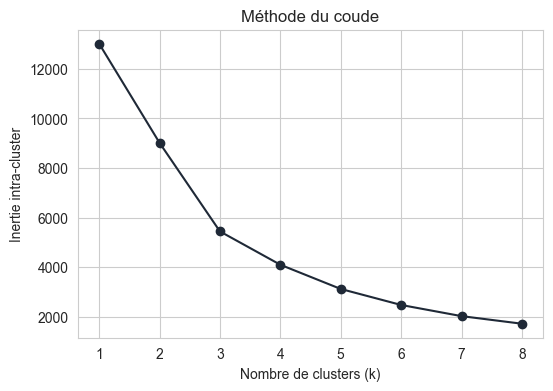

In [20]:
from sklearn.cluster import KMeans

colonnes_clustering = ["Recence", "Frequence", "Montant"]
X_cluster = rfm[colonnes_clustering].copy()

scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

inerties = []
for k in range(1, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster_scaled)
    inerties.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(range(1, 9), inerties, marker="o", color=COULEUR_MARINE)
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Inertie intra-cluster")
plt.title("Méthode du coude")
plt.show()

**Lecture du graphique :** le coude se situe autour de **k = 4** — on retient donc
4 segments de clients, un nombre classique en segmentation RFM (souvent présenté comme
"Champions / Fidèles / À relancer / Perdus" dans la littérature marketing).


In [21]:
k_optimal = 4
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
rfm["cluster"] = kmeans.fit_predict(X_cluster_scaled)

profil_clusters = rfm.groupby("cluster")[colonnes_clustering].mean().round(1)
profil_clusters["effectif"] = rfm["cluster"].value_counts().sort_index()
profil_clusters["%_VIP"] = (rfm.groupby("cluster")["VIP"].mean() * 100).round(1)
profil_clusters

,Recence,Frequence,Montant,effectif,%_VIP
cluster,,,,,
0,43.7,3.7,1353.6,3054,57.7
1,248.1,1.6,478.8,1067,17.7
2,7.4,82.5,127188.0,13,100.0
3,15.5,22.3,12690.5,204,100.0


In [22]:
pd.crosstab(rfm["cluster"], rfm["VIP"], normalize="index").round(3) * 100

VIP,0,1
cluster,,
0,42.3,57.7
1,82.3,17.7
2,0.0,100.0
3,0.0,100.0


C:\Users\Dell\AppData\Local\Temp\ipykernel_10556\1467769115.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=profil_clusters.index, y=profil_clusters["%_VIP"], palette="Set2", ax=axes[1])


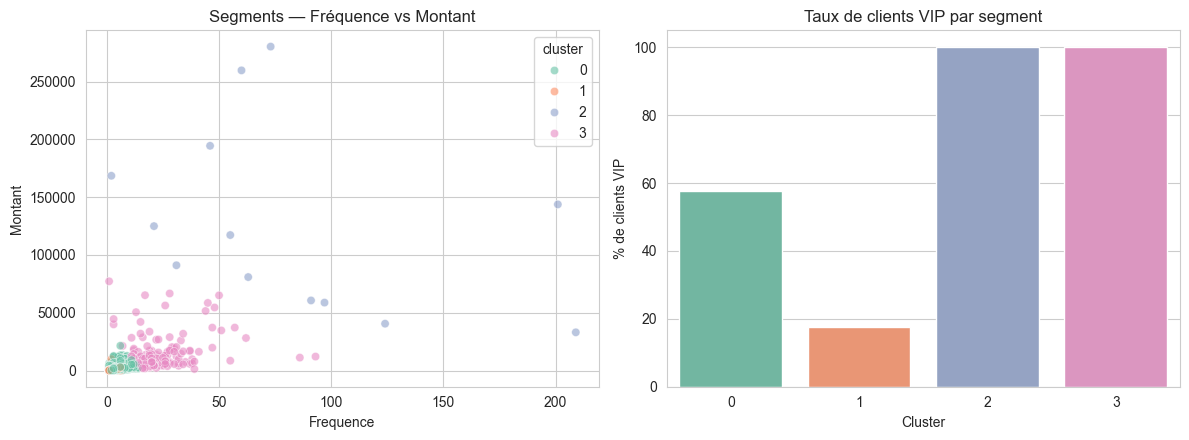

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.scatterplot(x="Frequence", y="Montant", hue="cluster", palette="Set2",
                 data=rfm, alpha=0.6, ax=axes[0])
axes[0].set_title("Segments — Fréquence vs Montant")

sns.barplot(x=profil_clusters.index, y=profil_clusters["%_VIP"], palette="Set2", ax=axes[1])
axes[1].set_ylabel("% de clients VIP")
axes[1].set_xlabel("Cluster")
axes[1].set_title("Taux de clients VIP par segment")

plt.tight_layout()
plt.show()

**Interprétation métier des 4 segments obtenus :**

| Cluster | Profil | Récence (j) | Fréquence | Montant moy. | Effectif | % VIP |
|---|---|---|---|---|---|---|
| 2 | **Hyper-champions** (grossistes) | 7,4 | 82,5 | **127 188 £** | 13 (0,3%) | **100%** |
| 3 | **Champions** | 15,5 | 22,3 | 12 690 £ | 204 (4,7%) | **100%** |
| 0 | **Clients standards actifs** | 43,7 | 3,7 | 1 354 £ | 3 054 (70,4%) | 57,7% |
| 1 | **Clients dormants** | 248,1 | 1,6 | 479 £ | 1 067 (24,6%) | 17,7% |

- **Clusters 2 et 3 ("Champions")** représentent moins de 5% des clients mais sont
  **VIP à 100%** — ce sont probablement en partie des acheteurs professionnels/revendeurs
  (82 commandes en moyenne pour le cluster 2). Un traitement dédié (compte grand
  compte, conditions préférentielles) maximiserait leur rétention, un enjeu majeur puisque
  perdre un seul de ces 13 clients représente l'équivalent de dizaines de clients standards.
- **Cluster 1 ("dormants")** : dernier achat il y a **8 mois en moyenne** (248 jours), pour
  seulement 17,7% de VIP. C'est le segment prioritaire pour une **campagne de réactivation**
  (relance email, code promo) avant qu'ils ne soient définitivement perdus.
- **Cluster 0** est le cœur de la base client (70,4% des clients) avec un taux de VIP proche
  de la moyenne — c'est le segment où une action marketing standard (newsletter, programme
  de fidélité classique) est la plus rentable en volume.

→ **Valeur ajoutée par rapport à la seule prédiction individuelle :** la segmentation RFM
révèle une réalité invisible dans un score individuel — une poignée de 13 clients "hyper-
champions" pèse potentiellement plus dans le chiffre d'affaires que des centaines de clients
standards réunis. Elle transforme un score par client en une **grille de priorisation
budgétaire concrète** : compte dédié pour les champions, campagne de réactivation ciblée
pour les dormants, communication de masse pour le cœur de base.

## 11. Pour aller plus loin : comparaison de méthodes

Cette section complète le pipeline principal en comparant chacune de mes deux méthodes
(prédictive et descriptive) à une alternative vue en cours, afin de vérifier la robustesse
de mes choix méthodologiques (Séance 4).


### 11.1 Régression logistique vs Arbre de décision

**Objectif :** vérifier si un modèle plus flexible (arbre de décision) capture mieux la
non-linéarité éventuelle entre les variables RFM et le statut VIP, ou si la régression
logistique déjà utilisée reste compétitive.


In [24]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight="balanced")
tree.fit(X_train_scaled, y_train)

y_pred_tree = tree.predict(X_test_scaled)
y_proba_tree = tree.predict_proba(X_test_scaled)[:, 1]

print("=== Arbre de décision (max_depth=4) ===")
print("Accuracy  :", round(accuracy_score(y_test, y_pred_tree), 3))
print("Précision :", round(precision_score(y_test, y_pred_tree), 3))
print("Rappel    :", round(recall_score(y_test, y_pred_tree), 3))
print("F1-score  :", round(f1_score(y_test, y_pred_tree), 3))
print("AUC       :", round(roc_auc_score(y_test, y_proba_tree), 3))

=== Arbre de décision (max_depth=4) ===
Accuracy  : 0.834
Précision : 0.839
Rappel    : 0.827
F1-score  : 0.833
AUC       : 0.908


In [25]:
comparaison = pd.DataFrame({
    "Régression logistique": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_proba),
    ],
    "Arbre de décision": [
        accuracy_score(y_test, y_pred_tree),
        precision_score(y_test, y_pred_tree),
        recall_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_tree),
        roc_auc_score(y_test, y_proba_tree),
    ],
}, index=["Accuracy", "Précision", "Rappel", "F1-score", "AUC"]).round(3)

comparaison

,Régression logistique,Arbre de décision
Accuracy,0.836,0.834
Précision,0.849,0.839
Rappel,0.818,0.827
F1-score,0.833,0.833
AUC,0.911,0.908


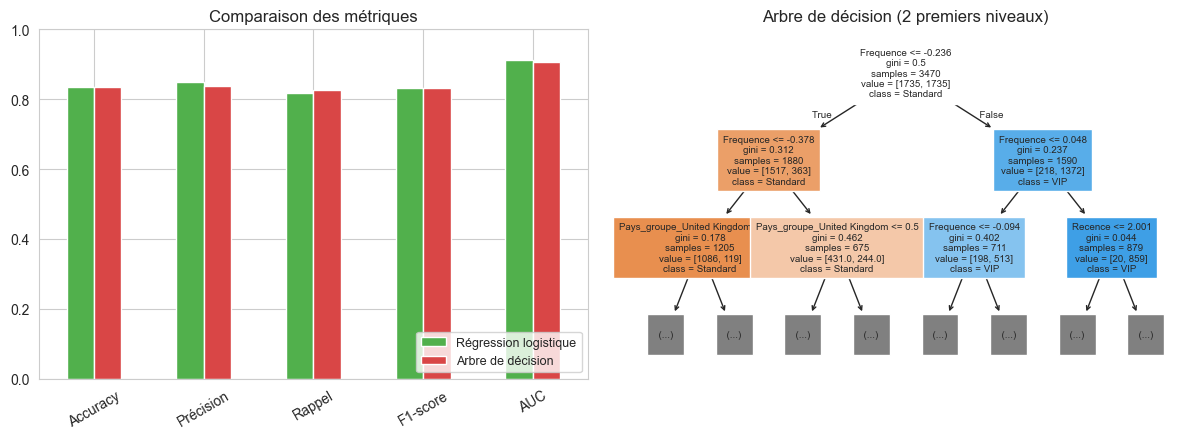

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

comparaison.plot(kind="bar", ax=axes[0], color=["#51b04c", "#d94646"])
axes[0].set_title("Comparaison des métriques")
axes[0].set_ylim(0, 1)
axes[0].legend(loc="lower right", fontsize=9)
axes[0].tick_params(axis="x", rotation=30)

from sklearn.tree import plot_tree
plot_tree(tree, max_depth=2, feature_names=X_train_scaled.columns, class_names=["Standard", "VIP"],
          filled=True, fontsize=7, ax=axes[1])
axes[1].set_title("Arbre de décision (2 premiers niveaux)")

plt.tight_layout()
plt.show()

**Interprétation :** les deux modèles obtiennent des performances quasiment identiques
(AUC 0,911 pour la régression logistique contre 0,908 pour l'arbre de décision, un écart de
0,003 seulement — F1-score strictement égal à 0,833 pour les deux). Cette égalité de
performance est un résultat important : elle confirme que la relation entre les variables RFM
et le statut VIP est majoritairement **linéaire**, ou du moins très bien approximée par un
modèle linéaire. Un arbre de décision, capable de capturer des interactions et seuils
non-linéaires complexes, n'apporte ici aucun gain mesurable.

Cela **justifie a posteriori mon choix initial de la régression logistique** (section 2.2) :
à performance égale, je préfère le modèle le plus interprétable (odds ratio directement
lisibles par une équipe marketing) plutôt qu'un modèle plus complexe qui n'apporterait rien de
plus en pratique. C'est un argument méthodologique concret que je peux défendre à l'oral si le
jury demande pourquoi je n'ai pas utilisé une méthode plus sophistiquée.


### 11.2 Validation de la stabilité des clusters K-means par CAH

**Objectif :** vérifier que les 4 segments trouvés par K-means (section 10) ne sont pas un
artefact de cet algorithme en particulier, en les comparant à ceux obtenus par une CAH
(Classification Ascendante Hiérarchique, linkage Ward) — une méthode fondamentalement
différente qui ne nécessite pas de fixer $k$ à l'avance.


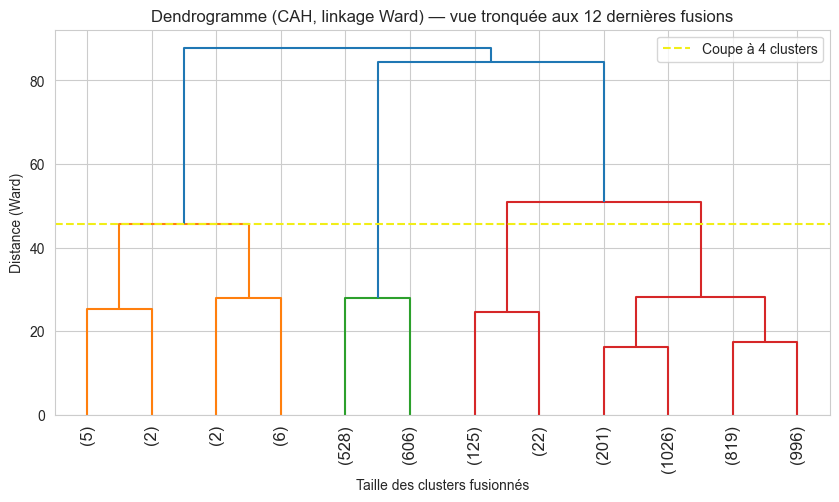

In [27]:
from scipy.cluster.hierarchy import dendrogram, linkage

Z = linkage(X_cluster_scaled, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode="lastp", p=12, leaf_rotation=90.)
plt.axhline(y=Z[-4, 2], color="#f1ee18", linestyle="--", label="Coupe à 4 clusters")
plt.title("Dendrogramme (CAH, linkage Ward) — vue tronquée aux 12 dernières fusions")
plt.xlabel("Taille des clusters fusionnés")
plt.ylabel("Distance (Ward)")
plt.legend()
plt.show()

In [28]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

cah = AgglomerativeClustering(n_clusters=4, linkage="ward")
rfm["cluster_cah"] = cah.fit_predict(X_cluster_scaled)

# Tableau croisé : les clusters K-means correspondent-ils aux clusters CAH ?
crosstab_stabilite = pd.crosstab(rfm["cluster"], rfm["cluster_cah"])
print(crosstab_stabilite)

ari = adjusted_rand_score(rfm["cluster"], rfm["cluster_cah"])
print(f"\nAdjusted Rand Index (K-means vs CAH) : {ari:.3f}")
print("(0 = accord aléatoire, 1 = accord parfait entre les deux méthodes)")

cluster_cah   0     1     2    3
cluster                         
0             0  2987    67    0
1             0     0  1067    0
2            13     0     0    0
3             2    55     0  147

Adjusted Rand Index (K-means vs CAH) : 0.904
(0 = accord aléatoire, 1 = accord parfait entre les deux méthodes)


**Interprétation :** le tableau croisé montre une correspondance quasi parfaite entre les
deux méthodes, une fois qu'on tient compte du fait que les numéros de cluster n'ont pas de
sens absolu d'un algorithme à l'autre (le cluster 0 de K-means correspond à la colonne 1 de la
CAH, etc.) :
- Les 13 clients du cluster « Hyper-champions » (K-means, cluster 2) se retrouvent
  **exactement** dans un seul cluster CAH (colonne 0) — correspondance parfaite.
- Les 1 067 clients « Dormants » (K-means, cluster 1) se retrouvent **exactement** dans un
  seul cluster CAH (colonne 2) — là encore, correspondance parfaite.
- Les segments « Standards actifs » et « Champions » se recoupent presque intégralement
  (2 987 clients sur 3 054, et 147 sur 204 respectivement), avec seulement quelques dizaines
  de clients à la frontière entre les deux méthodes.

L'**Adjusted Rand Index de 0,904** confirme rigoureusement cette observation visuelle — une
valeur aussi proche de 1 indique un accord très fort entre les deux méthodes (0 correspondrait
à un accord aléatoire). Deux algorithmes de clustering fondamentalement différents (K-means,
qui minimise la variance intra-cluster autour de centroïdes, contre la CAH, qui fusionne
progressivement les points les plus proches) aboutissent donc à la **même lecture du marché
client**. Cela renforce significativement la confiance dans les 4 segments présentés en
section 10 : ce ne sont pas un artefact du choix de K-means, mais une structure réelle et
robuste des données.


## 12. Conclusion et recommandations

**Ce que le pipeline apporte à l'entreprise (valeur ajoutée) :**

1. La régression logistique identifie les clients susceptibles de devenir VIP à partir de
   leur seul comportement d'achat (fréquence, récence), avant même que le montant cumulé
   ne le confirme — utile pour agir tôt.
2. Les **odds ratios** donnent des leviers directement compréhensibles par une équipe
   marketing non technique : la fréquence d'achat est le facteur numéro un.
3. La **segmentation RFM** (K-means) fournit une grille de lecture business immédiatement
   exploitable — un standard de l'industrie du marketing client, tous secteurs confondus.

**Limites :**
- Le dataset couvre une seule année (2010-2011) pour un seul site e-commerce britannique —
  les seuils RFM devraient être recalculés régulièrement en conditions réelles (le
  comportement d'achat évolue, notamment autour des périodes de soldes/fêtes).
- Le seuil VIP a été fixé arbitrairement à la médiane pour respecter la méthode du cours ;
  en entreprise, ce seuil serait défini avec les équipes métier selon un objectif de
  rentabilité (ex : top 20% des clients).

